<a href="https://colab.research.google.com/github/DonnyGit-08/solesearch-ai/blob/main/SoleSearch_02_train_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SoleSearch AI — Step 2: Train the sneaker classifier

This notebook fine-tunes **EfficientNet-B0** (pretrained on ImageNet) to recognize the sneaker models in `SoleSearch/train_data/`. It then evaluates the model on a held-out test set and saves everything the Streamlit app needs to `SoleSearch/models/`.

**Before you start:** go to **Runtime → Change runtime type → T4 GPU**. Training on CPU would take hours; on a T4 it takes about 10–20 minutes.

Run the cells top to bottom.

## 1. Setup: Drive, GPU, random seed

In [3]:
from google.colab import drive
drive.mount('/content/drive')

import json, random, shutil, time
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn

PROJECT = Path('/content/drive/MyDrive/SoleSearch')
DRIVE_DATA = PROJECT / 'train_data'
MODEL_DIR = PROJECT / 'models'
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# A fixed seed makes the train/val/test split the same every run,
# so your results are reproducible (worth mentioning in the report).
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)
if device == 'cpu':
    print('WARNING: no GPU found. Go to Runtime > Change runtime type > T4 GPU, then re-run.')

Mounted at /content/drive
Device: cuda


## 2. Copy the images from Drive to Colab

Reading thousands of small files straight from Drive is slow, so we copy them to Colab's local disk once. This copy disappears when the runtime shuts down, which is fine because the originals stay in Drive.

If you add more images to Drive later, set `FORCE_RECOPY = True` and re-run this cell.

In [4]:
FORCE_RECOPY = False
LOCAL_DATA = Path('/content/train_data')

if FORCE_RECOPY and LOCAL_DATA.exists():
    shutil.rmtree(LOCAL_DATA)
if not LOCAL_DATA.exists():
    print('Copying from Drive (a few minutes)...')
    shutil.copytree(DRIVE_DATA, LOCAL_DATA)

print(f'{"class":18s} images')
for d in sorted(p for p in LOCAL_DATA.iterdir() if p.is_dir()):
    print(f'{d.name:18s} {len(list(d.glob("*.jpg")))}')

Copying from Drive (a few minutes)...
class              images
adidas_samba       74
air_jordan_1       156
air_jordan_4       150
new_balance_550    150
nike_air_force_1   382
nike_dunk_low      80
yeezy_boost_350    148


## 3. Split the data and set up augmentation

- **70% train / 15% validation / 15% test**, stratified so every class appears in each split in the same proportion.
- The **test set is never used during training**. It's only used once, at the end, to report honest accuracy.
- **Augmentation** (random crops, flips, small rotations, brightness/contrast changes) shows the model varied versions of each photo, which helps it handle real user uploads.
- There is deliberately **no hue/color shift**, because color is what tells colorways apart later.

In [5]:
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset, DataLoader

IMG_SIZE = 224
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # ImageNet values EfficientNet expects

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

base = datasets.ImageFolder(LOCAL_DATA)
class_names = base.classes
labels = np.array(base.targets)
counts_all = np.bincount(labels, minlength=len(class_names))

too_small = [c for c, n in zip(class_names, counts_all) if n < 20]
if too_small:
    raise ValueError(f'These classes have fewer than 20 images: {too_small}. '
                     'Add more images or remove the folder, then re-run from step 2.')

idx = np.arange(len(labels))
train_idx, temp_idx = train_test_split(idx, test_size=0.30, stratify=labels, random_state=SEED)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, stratify=labels[temp_idx], random_state=SEED)

# ImageFolder always sorts files the same way, so the same indices point to the same images.
train_ds = Subset(datasets.ImageFolder(LOCAL_DATA, transform=train_tf), train_idx)
val_ds   = Subset(datasets.ImageFolder(LOCAL_DATA, transform=eval_tf), val_idx)
test_ds  = Subset(datasets.ImageFolder(LOCAL_DATA, transform=eval_tf), test_idx)

BATCH = 32
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)

# Save which images went into the test set, so the app's colorway gallery can avoid them.
split = {name: [str(Path(base.samples[i][0]).relative_to(LOCAL_DATA)) for i in ids]
         for name, ids in [('train', train_idx), ('val', val_idx), ('test', test_idx)]}
(MODEL_DIR / 'split.json').write_text(json.dumps(split, indent=1))

print(f'{len(class_names)} classes | train {len(train_idx)}, val {len(val_idx)}, test {len(test_idx)}')

7 classes | train 798, val 171, test 171


## 4. Build the model

We load EfficientNet-B0 with ImageNet weights, so it already knows shapes, edges, and textures. Then we replace its final layer (1,000 ImageNet classes) with a new one for our sneaker classes. This is called **transfer learning**.

The loss is **class-weighted**: if one sneaker has fewer photos, its mistakes count more, so the model doesn't just learn to guess the most common class.

In [6]:
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

model = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, len(class_names))
model = model.to(device)

train_counts = np.bincount(labels[train_idx], minlength=len(class_names))
class_weights = torch.tensor(train_counts.sum() / (len(train_counts) * train_counts),
                             dtype=torch.float32, device=device)
criterion = nn.CrossEntropyLoss(weight=class_weights)
scaler = torch.amp.GradScaler('cuda', enabled=(device == 'cuda'))  # mixed precision = faster on T4

print('Trainable parameters:', sum(p.numel() for p in model.parameters()))

Trainable parameters: 4016515


## 5. Train

Training happens in two phases:
1. **Head only (3 epochs):** the pretrained backbone is frozen and only the new final layer learns. This quickly gets a sensible starting point.
2. **Fine-tune everything (up to 15 epochs):** all layers learn with a smaller learning rate, adapting the backbone to sneaker details.

After every epoch the model is checked on the validation set, and the best version is saved. If validation accuracy stops improving for 4 epochs, training stops early to avoid overfitting.

In [7]:
history = []
best_acc = 0.0
BEST_PATH = MODEL_DIR / 'best_weights.pt'

def run_epoch(loader, train, optimizer=None):
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=(device == 'cuda')):
                out = model(x)
                loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

def train_phase(name, epochs, lr, freeze_backbone, patience=4):
    global best_acc
    for p in model.features.parameters():
        p.requires_grad = not freeze_backbone
    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],
                                  lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    bad_epochs = 0
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(train_loader, True, optimizer)
        va_loss, va_acc = run_epoch(val_loader, False)
        scheduler.step()
        history.append(dict(phase=name, train_loss=tr_loss, train_acc=tr_acc,
                            val_loss=va_loss, val_acc=va_acc))
        note = ''
        if va_acc > best_acc:
            best_acc, bad_epochs = va_acc, 0
            torch.save(model.state_dict(), BEST_PATH)
            note = '  <- best so far, saved'
        else:
            bad_epochs += 1
        print(f'[{name}] epoch {epoch:2d}/{epochs}  train acc {tr_acc:.3f}  '
              f'val acc {va_acc:.3f}  val loss {va_loss:.3f}  ({time.time() - t0:.0f}s){note}')
        if bad_epochs >= patience:
            print('Stopping early: validation accuracy stopped improving.')
            break

train_phase('head', epochs=3, lr=1e-3, freeze_backbone=True)
train_phase('finetune', epochs=15, lr=1e-4, freeze_backbone=False)
print(f'\nBest validation accuracy: {best_acc:.3f}')

[head] epoch  1/3  train acc 0.311  val acc 0.491  val loss 1.647  (13s)  <- best so far, saved
[head] epoch  2/3  train acc 0.521  val acc 0.538  val loss 1.495  (4s)  <- best so far, saved
[head] epoch  3/3  train acc 0.571  val acc 0.526  val loss 1.462  (3s)
[finetune] epoch  1/15  train acc 0.630  val acc 0.684  val loss 1.069  (10s)  <- best so far, saved
[finetune] epoch  2/15  train acc 0.731  val acc 0.737  val loss 0.775  (4s)  <- best so far, saved
[finetune] epoch  3/15  train acc 0.793  val acc 0.819  val loss 0.609  (6s)  <- best so far, saved
[finetune] epoch  4/15  train acc 0.823  val acc 0.813  val loss 0.507  (4s)
[finetune] epoch  5/15  train acc 0.863  val acc 0.871  val loss 0.441  (5s)  <- best so far, saved
[finetune] epoch  6/15  train acc 0.886  val acc 0.848  val loss 0.410  (6s)
[finetune] epoch  7/15  train acc 0.921  val acc 0.877  val loss 0.383  (4s)  <- best so far, saved
[finetune] epoch  8/15  train acc 0.921  val acc 0.865  val loss 0.363  (4s)
[fine

## 6. Training curves

If **train accuracy keeps rising while validation accuracy flattens or drops**, the model is starting to memorize the training photos (overfitting). Early stopping already saved the best point. This chart is a good figure for your report.

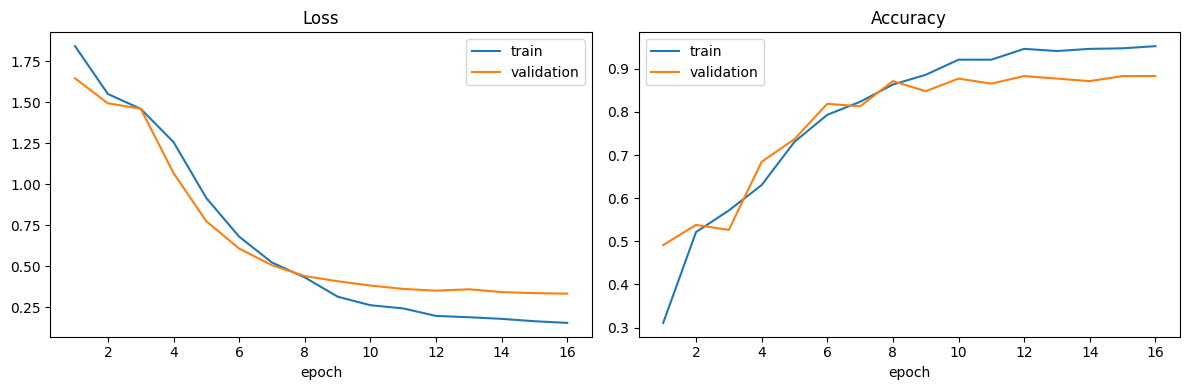

In [8]:
import matplotlib.pyplot as plt

ep = range(1, len(history) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ep, [h['train_loss'] for h in history], label='train')
axes[0].plot(ep, [h['val_loss'] for h in history], label='validation')
axes[0].set_title('Loss'); axes[0].set_xlabel('epoch'); axes[0].legend()
axes[1].plot(ep, [h['train_acc'] for h in history], label='train')
axes[1].plot(ep, [h['val_acc'] for h in history], label='validation')
axes[1].set_title('Accuracy'); axes[1].set_xlabel('epoch'); axes[1].legend()
plt.tight_layout()
plt.savefig(MODEL_DIR / 'training_curves.png', dpi=150)
plt.show()

## 7. Evaluate on the test set

This is the honest score: images the model has never seen. You get:
- **Top-1 accuracy:** the first guess is right.
- **Top-3 accuracy:** the right answer is somewhere in the top 3. This matters because the app shows the top 3 for the user to confirm.
- **Per-class precision and recall**, showing which sneakers are easy or hard.
- A **confusion matrix**, showing which sneakers get mixed up with each other.

Test top-1 accuracy: 0.895
Test top-3 accuracy: 0.982

                  precision    recall  f1-score   support

    adidas_samba      1.000     1.000     1.000        11
    air_jordan_1      0.815     0.917     0.863        24
    air_jordan_4      0.909     0.909     0.909        22
 new_balance_550      0.957     0.957     0.957        23
nike_air_force_1      0.958     0.807     0.876        57
   nike_dunk_low      0.611     0.917     0.733        12
 yeezy_boost_350      0.955     0.955     0.955        22

        accuracy                          0.895       171
       macro avg      0.886     0.923     0.899       171
    weighted avg      0.909     0.895     0.897       171



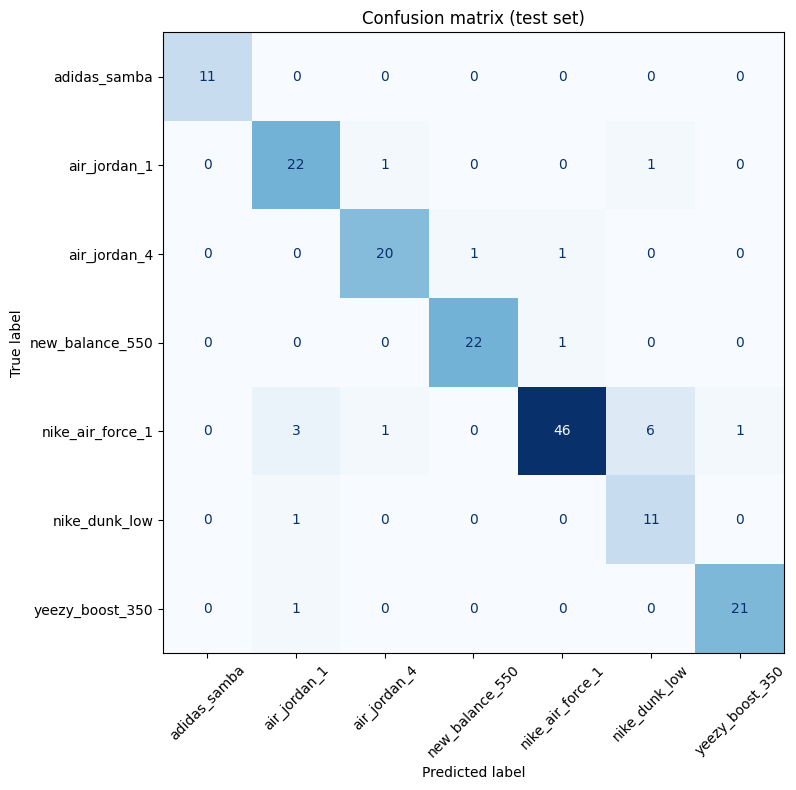

In [9]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

model.load_state_dict(torch.load(BEST_PATH, map_location=device))
model.eval()

all_probs, all_y = [], []
with torch.no_grad():
    for x, y in test_loader:
        all_probs.append(torch.softmax(model(x.to(device)), dim=1).cpu())
        all_y.append(y)
probs = torch.cat(all_probs).numpy()
y_true = torch.cat(all_y).numpy()
y_pred = probs.argmax(1)

top1 = float((y_pred == y_true).mean())
top3 = float(np.mean([t in np.argsort(p)[-3:] for p, t in zip(probs, y_true)]))
print(f'Test top-1 accuracy: {top1:.3f}')
print(f'Test top-3 accuracy: {top3:.3f}\n')
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=class_names,
                                        xticks_rotation=45, cmap='Blues', ax=ax, colorbar=False)
ax.set_title('Confusion matrix (test set)')
plt.tight_layout()
plt.savefig(MODEL_DIR / 'confusion_matrix.png', dpi=150)
plt.show()

## 8. Choose the app's "not sure" threshold

The app will say *"I'm not sure, here are the closest matches"* when the model's confidence is low. This table shows the trade-off for different thresholds:
- **Answered:** the share of photos where the model is confident enough to give a direct answer.
- **Accuracy when answered:** how often those confident answers are right.

Pick a threshold where accuracy is high but the app still answers most photos. That threshold is saved and used by the app.

In [10]:
conf = probs.max(1)
print(f'{"threshold":>9s} {"answered":>9s} {"accuracy when answered":>23s}')
for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    mask = conf >= t
    acc = (y_pred[mask] == y_true[mask]).mean() if mask.any() else float('nan')
    print(f'{t:9.1f} {mask.mean():9.1%} {acc:23.1%}')

CONFIDENCE_THRESHOLD = 0.6  # change this after looking at the table

threshold  answered  accuracy when answered
      0.3     97.7%                   89.8%
      0.4     93.0%                   89.9%
      0.5     88.9%                   91.4%
      0.6     81.9%                   95.7%
      0.7     74.3%                   96.9%
      0.8     66.7%                   97.4%
      0.9     59.1%                   99.0%


## 9. Look at the mistakes

Seeing *why* the model got something wrong is the best material for the error-analysis part of your report. Common causes: two shoes in one photo, unusual angles, heavy shadows, or a mislabeled image in the dataset (if so, delete it from Drive and retrain).

18 mistakes out of 171 test images


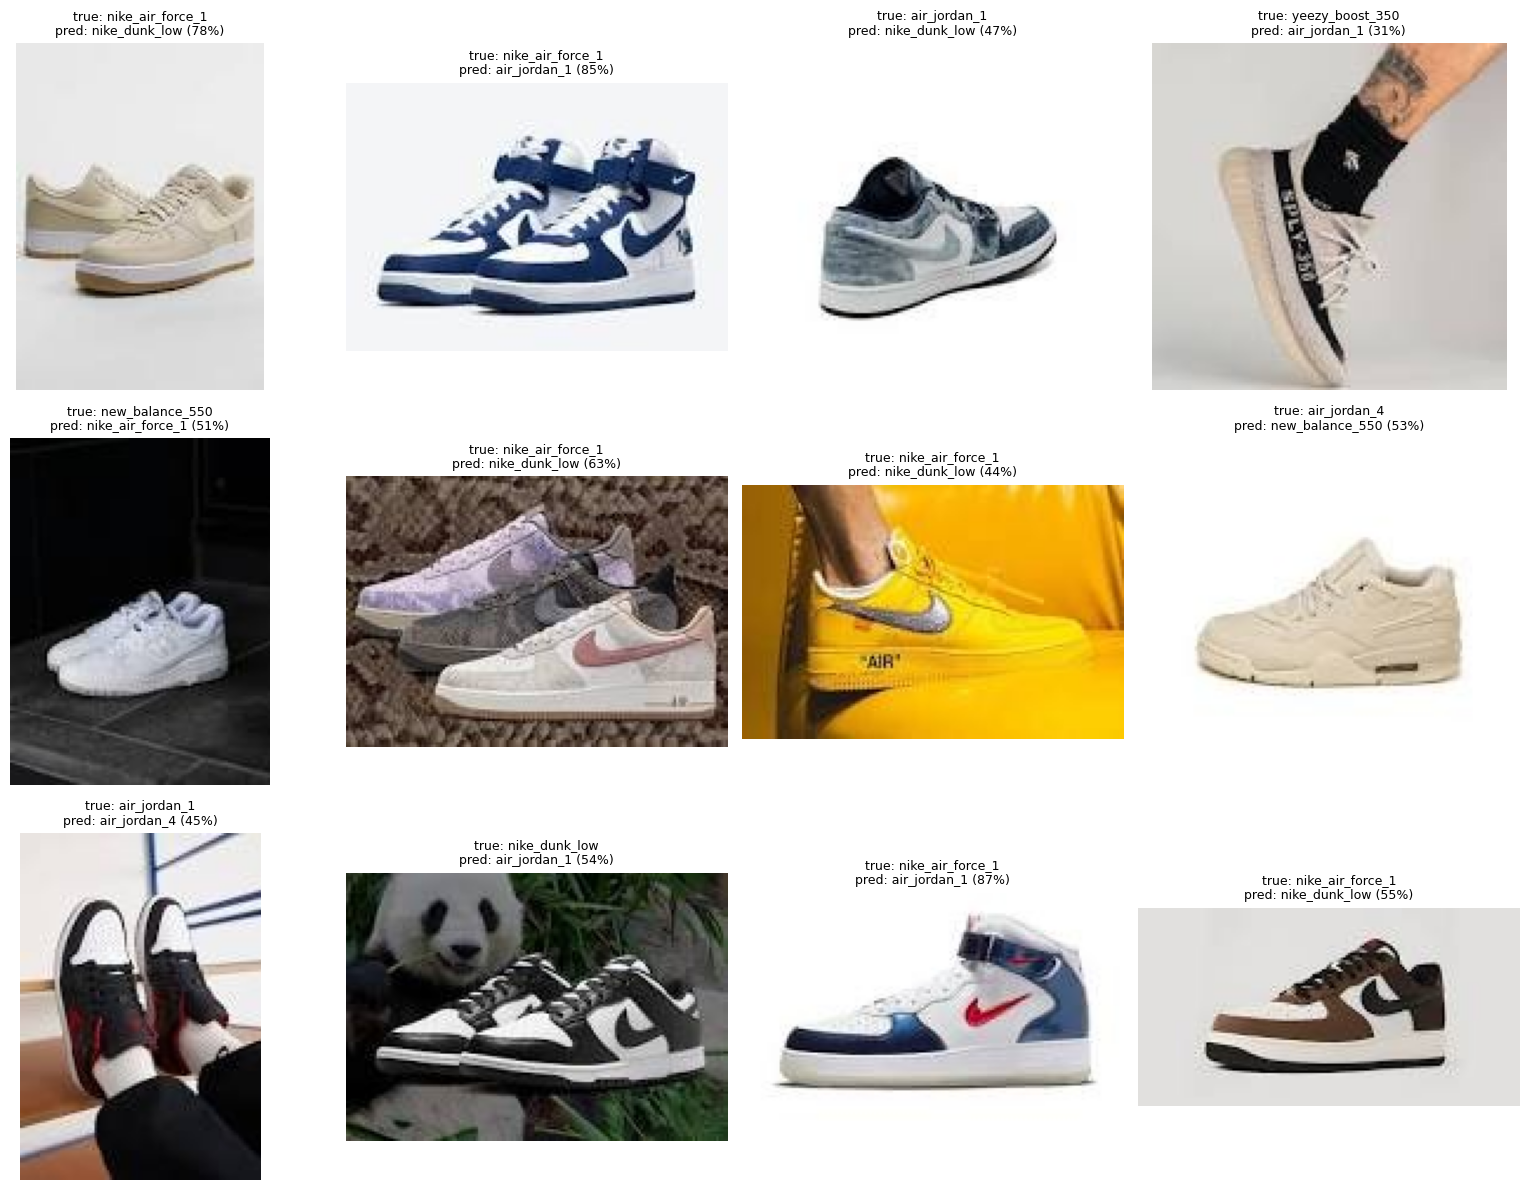

In [11]:
from PIL import Image

wrong = np.where(y_pred != y_true)[0]
print(f'{len(wrong)} mistakes out of {len(y_true)} test images')

show = wrong[:12]
if len(show):
    cols = 4
    rows = int(np.ceil(len(show) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
    for ax in np.array(axes).ravel():
        ax.axis('off')
    for ax, i in zip(np.array(axes).ravel(), show):
        path = base.samples[test_idx[i]][0]
        ax.imshow(Image.open(path).convert('RGB'))
        ax.set_title(f'true: {class_names[y_true[i]]}\npred: {class_names[y_pred[i]]} ({probs[i].max():.0%})',
                     fontsize=9)
    plt.tight_layout()
    plt.show()

## 10. Save the model for the app

This saves one file, `solesearch_effnet_b0.pt`, containing the trained weights plus everything the app needs to use them (class names, image size, normalization values, confidence threshold). Results go to `metrics.json` for your report.

When the Streamlit app is ready, you'll download this file from `SoleSearch/models/` in Drive into the app folder.

In [12]:
package = {
    'arch': 'efficientnet_b0',
    'state_dict': model.state_dict(),
    'class_names': class_names,
    'img_size': IMG_SIZE,
    'mean': MEAN,
    'std': STD,
    'confidence_threshold': CONFIDENCE_THRESHOLD,
}
torch.save(package, MODEL_DIR / 'solesearch_effnet_b0.pt')

metrics = {
    'test_top1_accuracy': top1,
    'test_top3_accuracy': top3,
    'best_val_accuracy': best_acc,
    'confidence_threshold': CONFIDENCE_THRESHOLD,
    'num_images': {'train': len(train_idx), 'val': len(val_idx), 'test': len(test_idx)},
    'class_names': class_names,
    'history': history,
}
(MODEL_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=1))

size_mb = (MODEL_DIR / 'solesearch_effnet_b0.pt').stat().st_size / 1e6
print(f'Saved model ({size_mb:.0f} MB) and metrics to {MODEL_DIR}')

Saved model (16 MB) and metrics to /content/drive/MyDrive/SoleSearch/models


## 11. Try it on your own photo

Upload any sneaker photo (your own shoes work best) and see the top 3 predictions.

Saving OIP.webp to OIP.webp


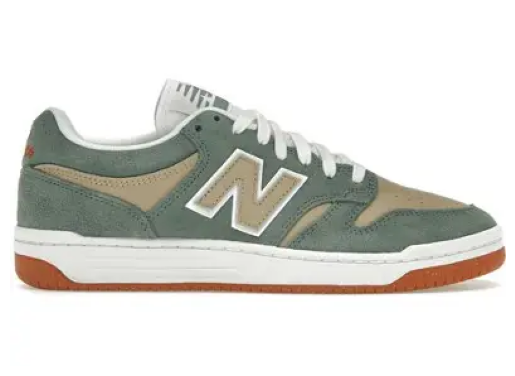

Not sure. Closest matches:
  new_balance_550    55.4%
  adidas_samba       22.4%
  nike_air_force_1   10.6%


In [13]:
from google.colab import files
import io

uploaded = files.upload()
for name, data in uploaded.items():
    img = Image.open(io.BytesIO(data)).convert('RGB')
    with torch.no_grad():
        p = torch.softmax(model(eval_tf(img).unsqueeze(0).to(device)), dim=1)[0].cpu().numpy()
    plt.imshow(img); plt.axis('off'); plt.show()
    top = np.argsort(p)[::-1][:3]
    if p[top[0]] < CONFIDENCE_THRESHOLD:
        print("Not sure. Closest matches:")
    for i in top:
        print(f'  {class_names[i]:18s} {p[i]:.1%}')